# Multi-Layer-Perceptron-Modell (MLP) (Wohnungsdaten)

In diesem Notebook werden wir ein Multi-Layer-Perceptron-Modell (MLP) verwenden, um die Mietpreise von Wohnungen vorherzusagen. Ein Multi-Layer-Perceptron-Modell (MLP) ist eine Art künstliches neuronales Netzwerk, das aus mehreren Schichten von Neuronen besteht. Jedes Neuron in einer Schicht ist mit jedem Neuron in der vorherigen und der nächsten Schicht verbunden, wodurch ein vollständig verbundenes Netzwerk entsteht. Das MLP-Modell ist in der Lage, durch Backpropagation und Gradientenabstieg komplexe Muster in den Daten zu lernen.

Die wichtigsten Komponenten eines MLP-Modells umfassen:

- **Input Layer (Eingabeschicht)**: Die Schicht, die die Eingabemerkmale empfängt.
- **Hidden Layers (versteckte Schichten)**: Eine oder mehrere Schichten mit Gewichten und Aktivierungsfunktionen, um Zwischenrepräsentationen zu lernen.
- **Output Layer (Ausgabeschicht)**: Die Schicht, die die endgültige Vorhersage erzeugt.

In diesem Notebook werden wir:

1. Die Wohnungsdaten vorverarbeiten, einschliesslich der Skalierung der Merkmale.
2. Das MLP-Modell mithilfe von TensorFlow/Keras definieren und kompilieren.
3. Das Modell mit den Trainingsdaten trainieren.
4. Das Modell anhand der Testdaten evaluieren.
5. Den Trainingsprozess und die Leistung des Modells visualisieren.


## Bibliotheken und Einstellungen

In [1]:
# Libraries
import os
import logging
import platform
import warnings
from datetime import datetime
from platform import python_version

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split

# Set TensorFlow log level to suppress warnings (must be set before
# TensorFlow is imported)
logging.disable(logging.WARNING)
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"

# TensorFlow and Keras (imported after setting the log level)
# pylint: disable=wrong-import-position
from tensorflow import keras

# pylint: enable=wrong-import-position

# Ignore warnings
warnings.filterwarnings('ignore')

# Show current working directory
print(os.getcwd())

I0000 00:00:1794655188.425309    6188 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794655188.431699    6188 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794655195.006533    6188 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794655195.008639    6188 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


/workspaces/python_machine_learning_basics/08_Neural_Networks


## Wohnungsdaten importieren

In [2]:
# Define columns for import
columns = [
    'web-scraper-order',
    'address_raw',
    'rooms',
    'area',
    'luxurious',
    'price',
    'price_per_m2',
    'lat',
    'lon',
    'bfs_number',
    'bfs_name',
    'pop',
    'pop_dens',
    'frg_pct',
    'emp',
    'mean_taxable_income',
    'dist_supermarket',
]

# Read and select variables
df_orig = pd.read_csv(
    "../00_Data/rental_apartments_canton_zh.csv", sep=";", encoding='utf-8'
)[columns]

# Remove missing values
df = df_orig.dropna()

# Remove duplicates
df = df.drop_duplicates()

# Remove some 'extreme' values
df = df.loc[(df['price'] >= 1000) & (df['price'] <= 5000)]

# Reset index
df = df.reset_index(drop=True)

# Shape and first rows of the cleaned data
print(df.shape)
df.head(5)

(722, 17)


,web-scraper-order,address_raw,rooms,area,luxurious,price,price_per_m2,lat,lon,bfs_number,bfs_name,pop,pop_dens,frg_pct,emp,mean_taxable_income,dist_supermarket
0,1693998201-1,"Neuhusstrasse 6, 8630 Rüti ZH, ZH",3.0,49,0,1441,29.41,47.252171,8.845797,118,Rüti (ZH),12286,1221.272366,24.841283,5053,65362.04268,645.652248
1,1693998233-172,"Widacherstrasse 5, 8630 Rüti ZH, ZH",3.0,111,0,2600,23.42,47.252087,8.854919,118,Rüti (ZH),12286,1221.272366,24.841283,5053,65362.04268,265.102153
2,1693998256-331,"Widenweg 14, 8630 Rüti ZH, ZH",3.0,58,0,1490,25.69,47.253670,8.853993,118,Rüti (ZH),12286,1221.272366,24.841283,5053,65362.04268,94.401821
3,1693998265-381,"Rain 1, 8630 Rüti ZH, ZH",4.0,118,0,3240,27.46,47.259834,8.851705,118,Rüti (ZH),12286,1221.272366,24.841283,5053,65362.04268,106.660970
4,1693998276-419,"Bachtelstrasse 24b, 8630 Rüti ZH, ZH",3.0,66,0,1450,21.97,47.266113,8.866872,118,Rüti (ZH),12286,1221.272366,24.841283,5053,65362.04268,974.844209


## Merkmale mithilfe eines Min-Max-Scalers skalieren

In [3]:
# List of features to re-scale
features_to_scale = [
    'area',
    'rooms',
    'lat',
    'lon',
    'pop',
    'pop_dens',
    'frg_pct',
    'emp',
    'mean_taxable_income',
    'dist_supermarket',
]

# Initialize the MinMaxScaler
scaler = MinMaxScaler()

# Fit and transform the features
df[features_to_scale] = scaler.fit_transform(df[features_to_scale])

## Trainings- und Testdatensätze erstellen (Training = 80 %, Test = 20 % der Daten)

In [4]:
# Create train and test samples
X_train, X_test, y_train, y_test = train_test_split(
    df[features_to_scale], df['price'], test_size=0.20, random_state=42
)

# Show X_train
print('X_train:')
print(X_train.head(), '\n')

# Show y_train
print('y_train:')
print(y_train.head())

X_train:
         area     rooms       lat       lon       pop  pop_dens   frg_pct  \
456  0.411765  0.846154  0.361445  0.887293  0.009952  0.016427  0.206503   
6    0.196078  0.384615  0.637867  0.195518  0.005904  0.093306  0.149322   
362  0.294118  0.384615  0.749858  0.192933  0.010772  0.071666  0.439201   
594  0.188235  0.230769  0.500230  0.406181  0.046320  0.203936  0.669363   
439  0.298039  0.384615  0.145885  1.000000  0.022402  0.066417  0.491679   

          emp  mean_taxable_income  dist_supermarket  
456  0.003682             0.030066          0.591051  
6    0.001043             0.439563          0.082871  
362  0.001985             0.090126          0.787478  
594  0.075905             0.079723          0.168520  
439  0.006783             0.000000          0.193446   

y_train:
456    1900
6      1850
362    2090
594    2102
439    1800
Name: price, dtype: int64


## Das Multi-Layer-Perceptron-Modell (MLP) trainieren

In [5]:
# Define the number of features
num_features = X_train.shape[1]

# Define the model
model = keras.Sequential(
    [
        keras.Input(shape=(num_features,)),
        keras.layers.Dense(256, activation='relu'),
        keras.layers.Dense(128, activation='relu'),
        keras.layers.Dense(64, activation='relu'),
        keras.layers.Dense(32, activation='relu'),
        keras.layers.Dense(1),
    ]
)

# Compile the model
model.compile(optimizer='adam', loss='mse', metrics=['mape'])

# Train the model
history = model.fit(
    X_train,
    y_train,
    epochs=100,
    validation_split=0.20,
    batch_size=32,
    verbose=0,
)

# Predict the response for test dataset
y_pred = model.predict(X_test)

# Evaluate the model on the test set (MAPE: mean absolute percentage error)
test_loss, test_mape = model.evaluate(X_test, y_test)
print("MAPE:", round(test_mape, 2))

# Calculate R2 score
r2 = r2_score(y_test, y_pred)
print("R2 score:", round(r2, 4))

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 300264.7812 - mape: 16.2763 
MAPE: 16.28
R2 score: 0.5814


## Trainings- und Validierungsverlustwerte grafisch darstellen

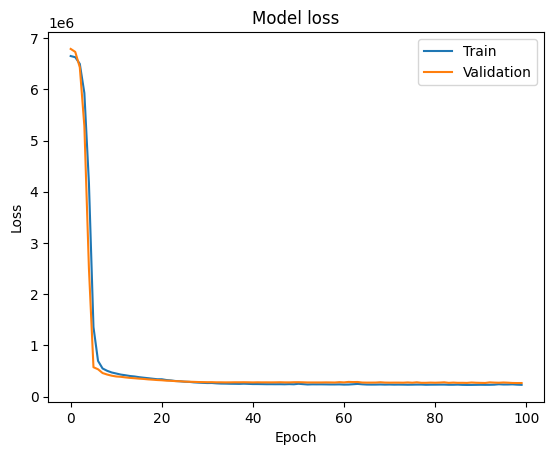

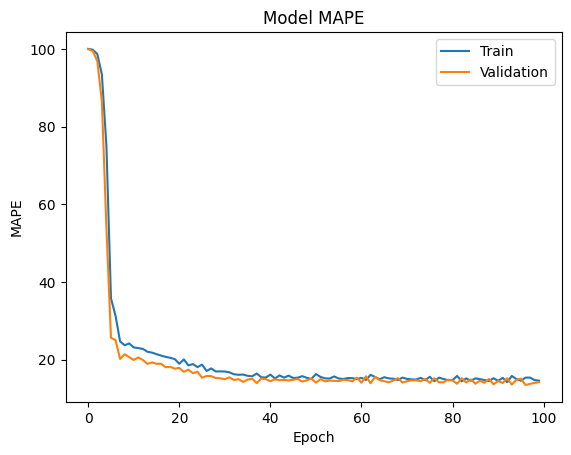

In [6]:
# Plot training & validation loss values
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper right')
plt.show()

# Plot training & validation MAPE values
plt.plot(history.history['mape'])
plt.plot(history.history['val_mape'])
plt.title('Model MAPE')
plt.ylabel('MAPE')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper right')
plt.show()

Was bedeuten die beiden Kurven im Jupyter Notebook?
Wenn du beim Training Model Loss und Model MAPE als zwei Diagramme siehst:
- Model Loss sinkt: Das Modell verbessert sich hinsichtlich seiner Loss Function.
- Model MAPE sinkt: Die durchschnittliche prozentuale Abweichung der Mietvorhersagen wird kleiner.
- Validation Loss steigt, während Training Loss sinkt: Das kann auf Overfitting hindeuten.
Prüfungsmerksatz:

Loss = Fehler, den das Modell beim Training minimieren soll.

MAPE = durchschnittlicher prozentualer Vorhersagefehler.

Achtung: Loss ist nicht automatisch MSE. Welche Loss Function dein MLP tatsächlich verwendet, steht im Code bei model.compile(loss=...). MAPE ist ausserdem bei tatsächlichen Werten von null nicht definiert.

### Jupyter Notebook – Abschlussinformationen (bitte immer am Ende jedes Notebooks angeben)

In [7]:
# Show operating system, date/time and Python version
print('-----------------------------------')
print(os.name.upper())
print(platform.system(), '|', platform.release())
print('Datetime:', datetime.now().strftime("%Y-%m-%d %H:%M:%S"))
print('Python Version:', python_version())
print('-----------------------------------')

-----------------------------------
POSIX
Linux | 6.8.0-1070-azure
Datetime: 2026-11-14 11:23:34
Python Version: 3.11.18
-----------------------------------
